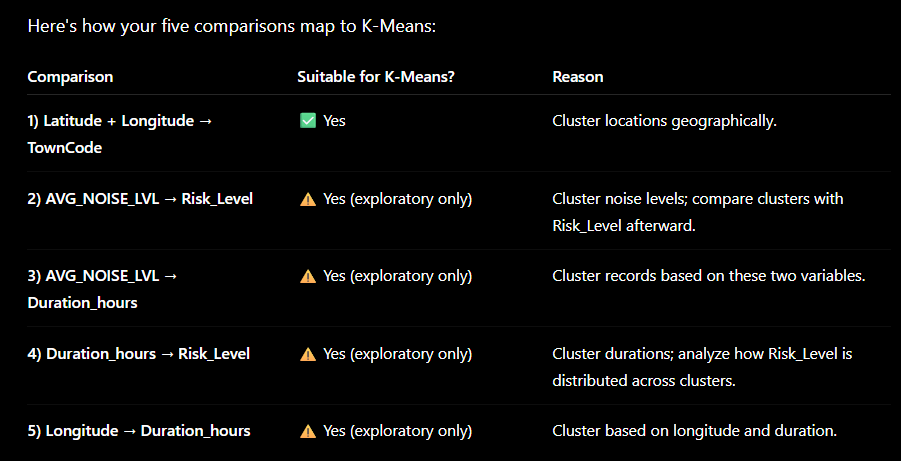

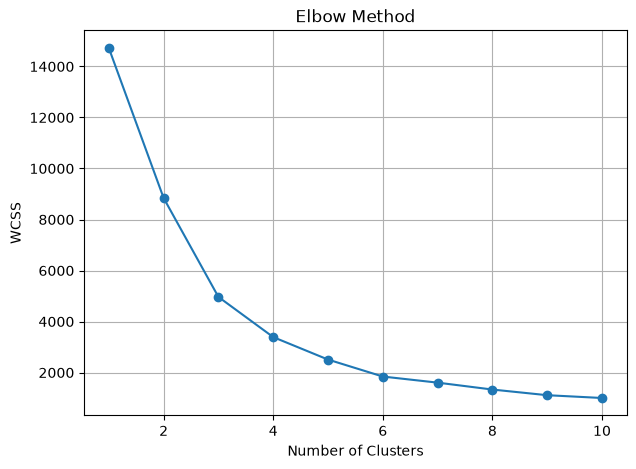


Cluster Centers

    LATITUDE  LONGITUDE
0  53.265449  17.774320
1  51.965102  22.234984
2  50.693463  18.212947

Silhouette Score = 0.4794

Cluster Distribution

Cluster
2    3502
1    1988
0    1872
Name: count, dtype: int64


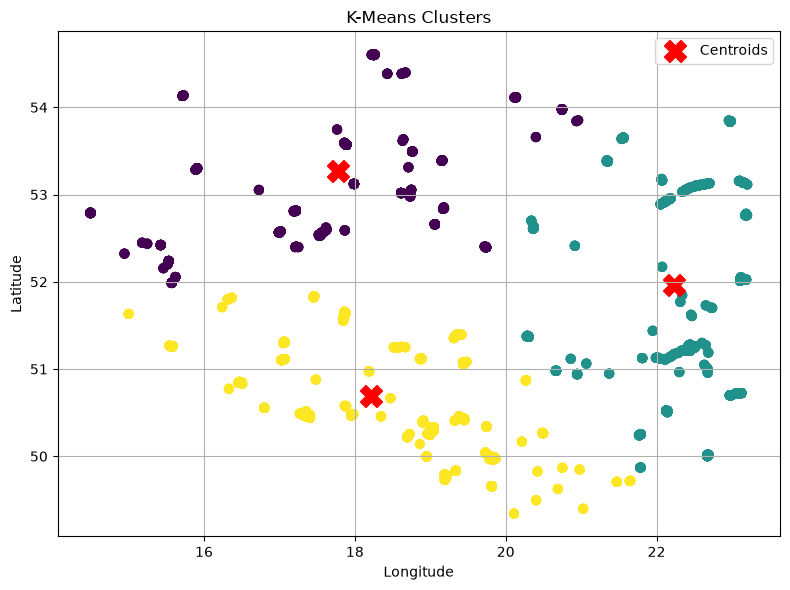


Cluster Summary

          LATITUDE  LONGITUDE
Cluster                      
0        53.265449  17.774320
1        51.965102  22.234984
2        50.693463  18.212947

Town Distribution

Cluster  TOWN           
0        Biskupiec           6
         Boczow              4
         Braciszewo          8
         Bydgoszcz          96
         Chociule            4
                            ..
2        Wtorek              4
         Wysocko Male        4
         Wysocko Wielkie    20
         Wyszkow Slaski      8
         Zolkow              8
Length: 167, dtype: int64

Results saved successfully.

K-Means Completed Successfully.


In [2]:
# ==========================================================
# K-MEANS CLUSTERING
# Latitude + Longitude
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Select Variables
# ==========================================================

df = df[["LATITUDE","LONGITUDE","TOWN"]]

df = df.dropna()

# ==========================================================
# Features
# ==========================================================

X = df[["LATITUDE","LONGITUDE"]]

# ==========================================================
# Standardization
# ==========================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# ==========================================================
# Elbow Method
# ==========================================================

wcss = []

for i in range(1,11):

    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

plt.figure(figsize=(7,5))

plt.plot(
    range(1,11),
    wcss,
    marker='o'
)

plt.xlabel("Number of Clusters")

plt.ylabel("WCSS")

plt.title("Elbow Method")

plt.grid(True)

plt.show()

# ==========================================================
# Build Final Model
# ==========================================================

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# ==========================================================
# Cluster Centers
# ==========================================================

centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centers = pd.DataFrame(
    centers,
    columns=["LATITUDE","LONGITUDE"]
)

print("\nCluster Centers\n")

print(centers)

# ==========================================================
# Silhouette Score
# ==========================================================

score = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("\nSilhouette Score =", round(score,4))

# ==========================================================
# Cluster Count
# ==========================================================

print("\nCluster Distribution\n")

print(df["Cluster"].value_counts())

# ==========================================================
# Scatter Plot
# ==========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    df["LONGITUDE"],
    df["LATITUDE"],
    c=df["Cluster"],
    cmap="viridis",
    s=40
)

plt.scatter(
    centers["LONGITUDE"],
    centers["LATITUDE"],
    marker="X",
    s=250,
    color="red",
    label="Centroids"
)

plt.xlabel("Longitude")

plt.ylabel("Latitude")

plt.title("K-Means Clusters")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Cluster Summary
# ==========================================================

summary = df.groupby("Cluster")[["LATITUDE","LONGITUDE"]].mean()

print("\nCluster Summary\n")

print(summary)

# ==========================================================
# Town Distribution
# ==========================================================

town_cluster = df.groupby(["Cluster","TOWN"]).size()

print("\nTown Distribution\n")

print(town_cluster)

# ==========================================================
# Save Output
# ==========================================================

df.to_excel(
    "KMeans_Latitude_Longitude.xlsx",
    index=False
)

print("\nResults saved successfully.")

print("\nK-Means Completed Successfully.")

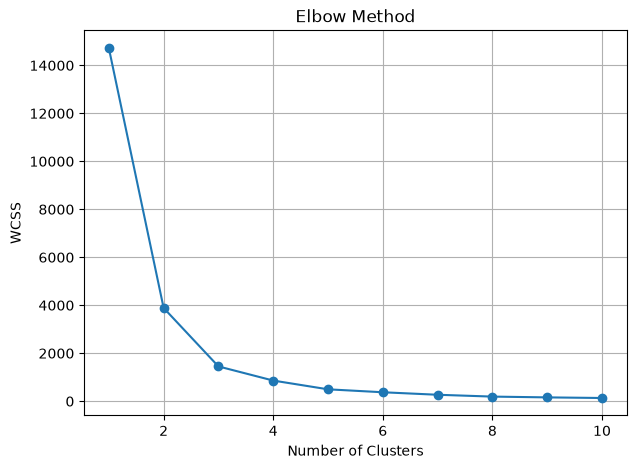


Cluster Centers

   AVG_NOISE_LVL  Risk_Level_Code
0      60.690310     2.000000e+00
1      68.696220     3.552714e-15
2      51.557261     1.000000e+00

Silhouette Score : 0.7477

Cluster Distribution

Cluster
0    3488
1    2910
2     964
Name: count, dtype: int64


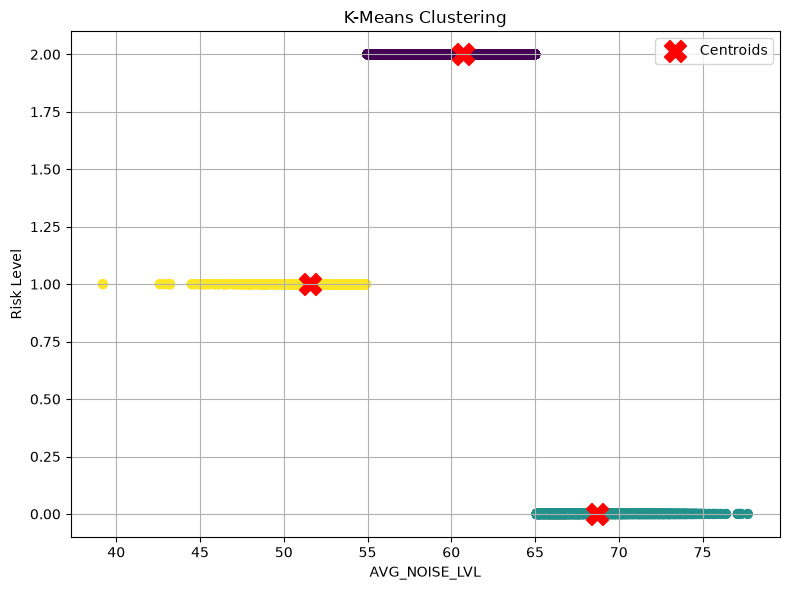


Cluster Summary

         AVG_NOISE_LVL  Risk_Level_Code
Cluster                                
0            60.690310              2.0
1            68.696220              0.0
2            51.557261              1.0

Risk Level Distribution

Risk_Level  High  Low  Moderate
Cluster                        
0              0    0      3488
1           2910    0         0
2              0  964         0

Results saved successfully.

K-Means Completed Successfully.


In [3]:
# ==========================================================
# K-MEANS CLUSTERING
# AVG_NOISE_LVL + Risk_Level
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import silhouette_score

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Select Required Columns
# ==========================================================

df = df[["AVG_NOISE_LVL", "Risk_Level"]]

df = df.dropna()

# ==========================================================
# Encode Risk Level
# ==========================================================

encoder = LabelEncoder()

df["Risk_Level_Code"] = encoder.fit_transform(df["Risk_Level"])

# ==========================================================
# Features
# ==========================================================

X = df[["AVG_NOISE_LVL", "Risk_Level_Code"]]

# ==========================================================
# Standardization
# ==========================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# ==========================================================
# Elbow Method
# ==========================================================

wcss = []

for i in range(1,11):

    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

plt.figure(figsize=(7,5))

plt.plot(range(1,11), wcss, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.grid(True)

plt.show()

# ==========================================================
# Final Model
# ==========================================================

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# ==========================================================
# Cluster Centers
# ==========================================================

centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centers = pd.DataFrame(
    centers,
    columns=["AVG_NOISE_LVL", "Risk_Level_Code"]
)

print("\nCluster Centers\n")

print(centers)

# ==========================================================
# Silhouette Score
# ==========================================================

score = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("\nSilhouette Score :", round(score,4))

# ==========================================================
# Cluster Distribution
# ==========================================================

print("\nCluster Distribution\n")

print(df["Cluster"].value_counts())

# ==========================================================
# Scatter Plot
# ==========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    df["AVG_NOISE_LVL"],
    df["Risk_Level_Code"],
    c=df["Cluster"],
    cmap="viridis",
    s=40
)

plt.scatter(
    centers["AVG_NOISE_LVL"],
    centers["Risk_Level_Code"],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("AVG_NOISE_LVL")

plt.ylabel("Risk Level")

plt.title("K-Means Clustering")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()

# ==========================================================
# Cluster Summary
# ==========================================================

summary = df.groupby("Cluster")[
    ["AVG_NOISE_LVL","Risk_Level_Code"]
].mean()

print("\nCluster Summary\n")

print(summary)

# ==========================================================
# Risk Level Distribution
# ==========================================================

print("\nRisk Level Distribution\n")

print(pd.crosstab(df["Cluster"], df["Risk_Level"]))

# ==========================================================
# Save Results
# ==========================================================

df.to_excel(
    "KMeans_Noise_Risk.xlsx",
    index=False
)

print("\nResults saved successfully.")

print("\nK-Means Completed Successfully.")

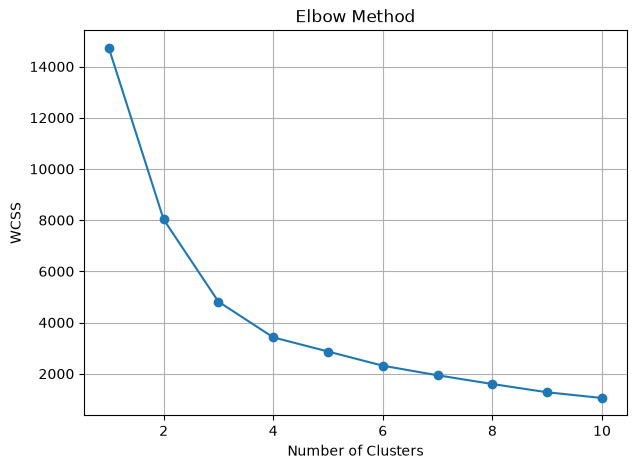

Cluster Centers
   AVG_NOISE_LVL  Duration_hours
0      66.154201       14.414368
1      54.730798        9.287072
2      65.361028        5.671028

Silhouette Score : 0.4704

Cluster Distribution
Cluster
0    3114
2    2140
1    2108
Name: count, dtype: int64


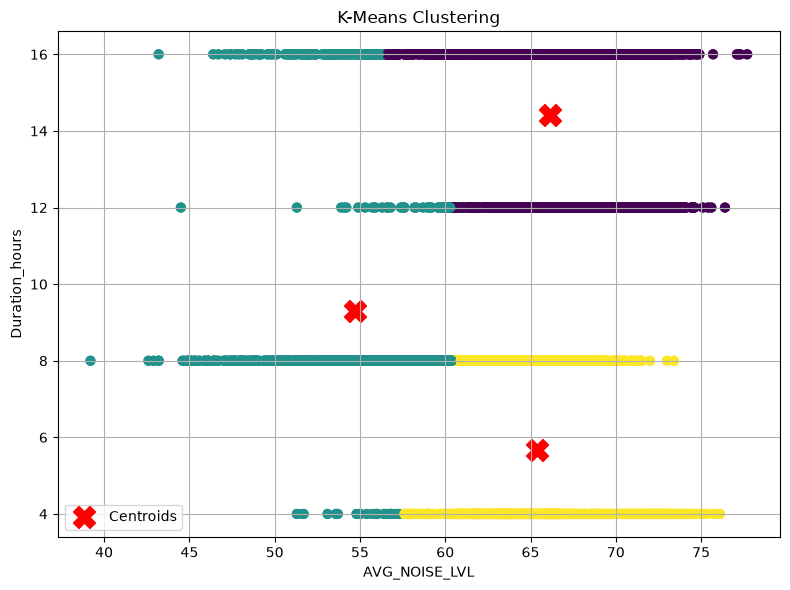


Cluster Summary
         AVG_NOISE_LVL  Duration_hours
Cluster                               
0            66.161721       14.417469
1            54.741366        9.292220
2            65.361028        5.671028

Descriptive Statistics by Cluster
        AVG_NOISE_LVL                       Duration_hours              \
                 mean   min   max       std           mean   min   max   
Cluster                                                                  
0           66.161721  56.5  77.7  4.087664      14.417469  12.0  16.0   
1           54.741366  39.2  60.4  3.647219       9.292220   4.0  16.0   
2           65.361028  57.6  76.1  3.799412       5.671028   4.0   8.0   

                   
              std  
Cluster            
0        1.956259  
1        3.004821  
2        1.973220  

Results saved successfully.

K-Means Completed Successfully.


In [4]:
# ==========================================================
# K-MEANS CLUSTERING
# AVG_NOISE_LVL + Duration_hours
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Select Variables
# ==========================================================

df = df[["AVG_NOISE_LVL","Duration_hours"]]

df = df.dropna()

# ==========================================================
# Features
# ==========================================================

X = df[["AVG_NOISE_LVL","Duration_hours"]]

# ==========================================================
# Standardization
# ==========================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# ==========================================================
# Elbow Method
# ==========================================================

wcss = []

for i in range(1,11):

    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

plt.figure(figsize=(7,5))

plt.plot(
    range(1,11),
    wcss,
    marker='o'
)

plt.xlabel("Number of Clusters")

plt.ylabel("WCSS")

plt.title("Elbow Method")

plt.grid(True)

plt.show()

# ==========================================================
# Final KMeans Model
# ==========================================================

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# ==========================================================
# Cluster Centers
# ==========================================================

centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centers = pd.DataFrame(
    centers,
    columns=["AVG_NOISE_LVL","Duration_hours"]
)

print("="*70)
print("Cluster Centers")
print("="*70)

print(centers)

# ==========================================================
# Silhouette Score
# ==========================================================

score = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("\nSilhouette Score :", round(score,4))

# ==========================================================
# Cluster Distribution
# ==========================================================

print("\nCluster Distribution")

print(df["Cluster"].value_counts())

# ==========================================================
# Scatter Plot
# ==========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    df["AVG_NOISE_LVL"],
    df["Duration_hours"],
    c=df["Cluster"],
    cmap="viridis",
    s=40
)

plt.scatter(
    centers["AVG_NOISE_LVL"],
    centers["Duration_hours"],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("AVG_NOISE_LVL")

plt.ylabel("Duration_hours")

plt.title("K-Means Clustering")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Cluster Summary
# ==========================================================

summary = df.groupby("Cluster")[
    ["AVG_NOISE_LVL","Duration_hours"]
].mean()

print("\nCluster Summary")

print(summary)

# ==========================================================
# Descriptive Statistics
# ==========================================================

print("\nDescriptive Statistics by Cluster")

print(
    df.groupby("Cluster").agg({
        "AVG_NOISE_LVL":["mean","min","max","std"],
        "Duration_hours":["mean","min","max","std"]
    })
)

# ==========================================================
# Save Results
# ==========================================================

df.to_excel(
    "KMeans_Noise_Duration.xlsx",
    index=False
)

print("\nResults saved successfully.")

print("\nK-Means Completed Successfully.")

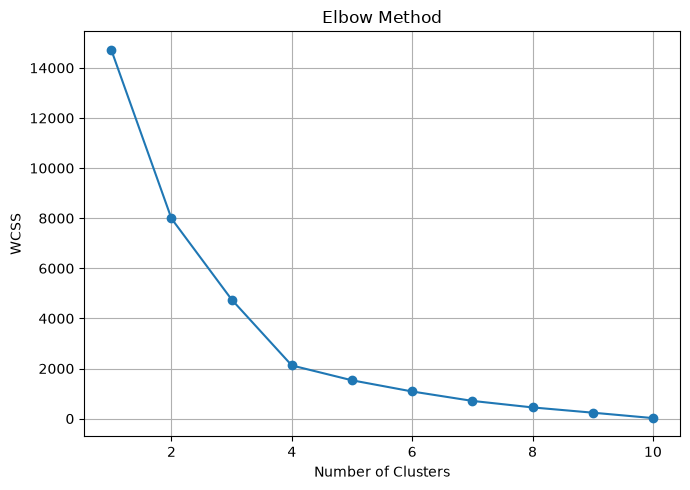

Cluster Centers
   Duration_hours  Risk_Level_Code
0       14.897984         1.859499
1       11.110198         0.004107
2        7.052444         1.742419

Silhouette Score : 0.5567

Cluster Distribution
Cluster
1    2922
2    2803
0    1637
Name: count, dtype: int64


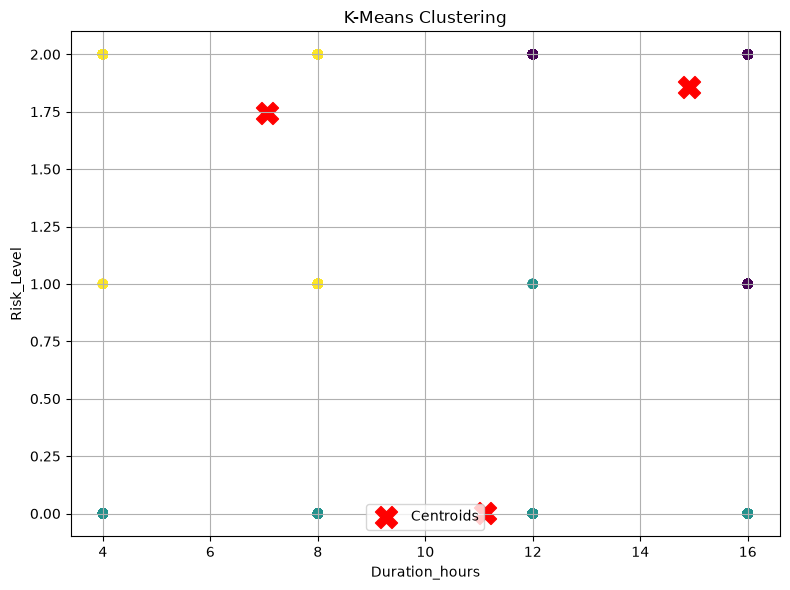


Cluster Summary
         Duration_hours  Risk_Level_Code
Cluster                                 
0             14.897984         1.859499
1             11.110198         0.004107
2              7.052444         1.742419

Risk Level Distribution by Cluster
Risk_Level  High  Low  Moderate
Cluster                        
0              0  230      1407
1           2910   12         0
2              0  722      2081

Descriptive Statistics
        Duration_hours                       Risk_Level_Code        
                  mean   min   max       std            mean min max
Cluster                                                             
0            14.897984  12.0  16.0  1.787618        1.859499   1   2
1            11.110198   4.0  16.0  4.555959        0.004107   0   1
2             7.052444   4.0   8.0  1.700998        1.742419   1   2

Results saved successfully.

K-Means Completed Successfully.


In [6]:
# ==========================================================
# K-MEANS CLUSTERING
# Duration_hours + Risk_Level
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import silhouette_score

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Select Variables
# ==========================================================

df = df[["Duration_hours","Risk_Level"]]

df = df.dropna()

# ==========================================================
# Encode Risk Level
# ==========================================================

encoder = LabelEncoder()

df["Risk_Level_Code"] = encoder.fit_transform(df["Risk_Level"])

# ==========================================================
# Features
# ==========================================================

X = df[["Duration_hours","Risk_Level_Code"]]

# ==========================================================
# Standardization
# ==========================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# ==========================================================
# Elbow Method
# ==========================================================

wcss = []

for i in range(1,11):

    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

plt.figure(figsize=(7,5))

plt.plot(
    range(1,11),
    wcss,
    marker='o'
)

plt.xlabel("Number of Clusters")

plt.ylabel("WCSS")

plt.title("Elbow Method")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Final KMeans Model
# ==========================================================

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# ==========================================================
# Cluster Centers
# ==========================================================

centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centers = pd.DataFrame(
    centers,
    columns=["Duration_hours","Risk_Level_Code"]
)

print("="*70)
print("Cluster Centers")
print("="*70)

print(centers)

# ==========================================================
# Silhouette Score
# ==========================================================

score = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("\nSilhouette Score :", round(score,4))

# ==========================================================
# Cluster Distribution
# ==========================================================

print("\nCluster Distribution")

print(df["Cluster"].value_counts())

# ==========================================================
# Scatter Plot
# ==========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    df["Duration_hours"],
    df["Risk_Level_Code"],
    c=df["Cluster"],
    cmap="viridis",
    s=40
)

plt.scatter(
    centers["Duration_hours"],
    centers["Risk_Level_Code"],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("Duration_hours")

plt.ylabel("Risk_Level")

plt.title("K-Means Clustering")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Cluster Summary
# ==========================================================

summary = df.groupby("Cluster")[
    ["Duration_hours","Risk_Level_Code"]
].mean()

print("\nCluster Summary")

print(summary)

# ==========================================================
# Risk Level Distribution
# ==========================================================

print("\nRisk Level Distribution by Cluster")

print(
    pd.crosstab(
        df["Cluster"],
        df["Risk_Level"]
    )
)

# ==========================================================
# Descriptive Statistics
# ==========================================================

print("\nDescriptive Statistics")

print(
    df.groupby("Cluster").agg({
        "Duration_hours":["mean","min","max","std"],
        "Risk_Level_Code":["mean","min","max"]
    })
)

# ==========================================================
# Save Results
# ==========================================================

df.to_excel(
    "KMeans_Duration_Risk.xlsx",
    index=False
)

print("\nResults saved successfully.")

print("\nK-Means Completed Successfully.")

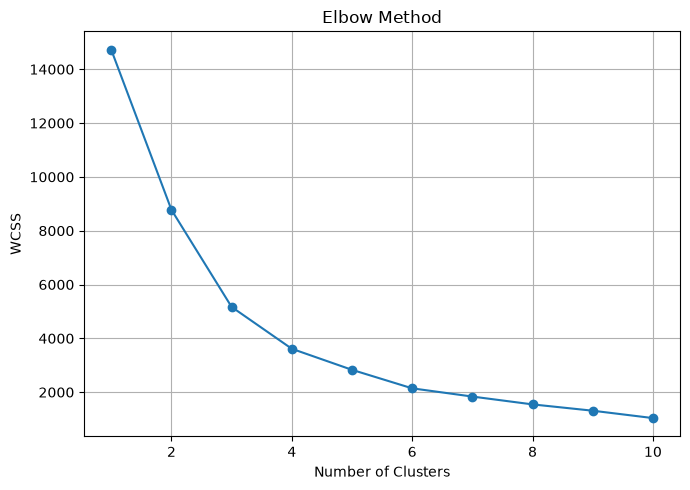

Cluster Centers
   LONGITUDE  Duration_hours
0  22.325256       10.725552
1  18.113957        6.523760
2  18.072658       14.517656

Silhouette Score : 0.4582

Cluster Distribution
Cluster
1    2883
2    2577
0    1902
Name: count, dtype: int64


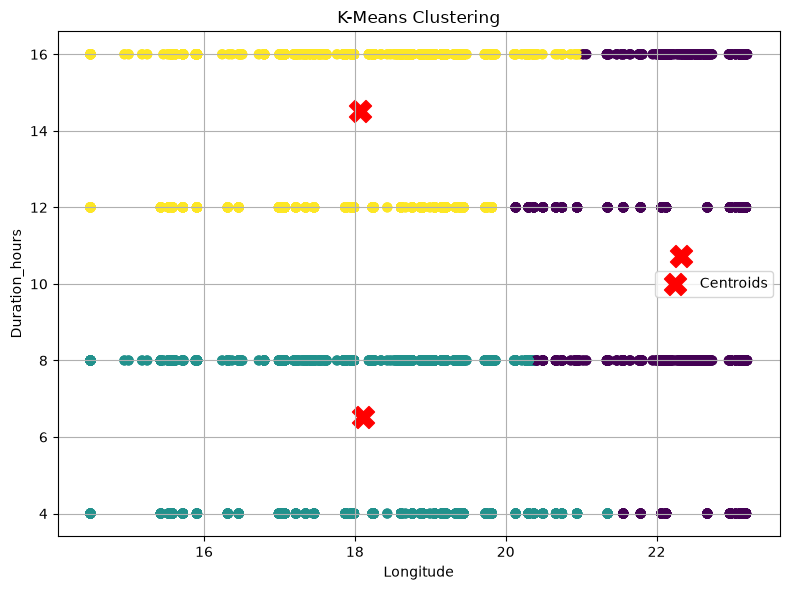


Cluster Summary
         LONGITUDE  Duration_hours
Cluster                           
0        22.325256       10.725552
1        18.113957        6.523760
2        18.072658       14.517656

Descriptive Statistics
         LONGITUDE                             Duration_hours              \
              mean      min      max       std           mean   min   max   
Cluster                                                                     
0        22.325256  20.1323  23.2018  0.796882      10.725552   4.0  16.0   
1        18.113957  14.4937  21.3511  1.454238       6.523760   4.0   8.0   
2        18.072658  14.4937  20.9809  1.372650      14.517656  12.0  16.0   

                   
              std  
Cluster            
0        4.128317  
1        1.930536  
2        1.932222  

Cluster Sizes
Cluster
1    2883
2    2577
0    1902
Name: count, dtype: int64

Results saved successfully.

K-Means Completed Successfully.


In [7]:
# ==========================================================
# K-MEANS CLUSTERING
# Longitude + Duration_hours
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Select Variables
# ==========================================================

df = df[["LONGITUDE","Duration_hours"]]

df = df.dropna()

# ==========================================================
# Features
# ==========================================================

X = df[["LONGITUDE","Duration_hours"]]

# ==========================================================
# Standardize Features
# ==========================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# ==========================================================
# Elbow Method
# ==========================================================

wcss = []

for i in range(1,11):

    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

plt.figure(figsize=(7,5))

plt.plot(
    range(1,11),
    wcss,
    marker='o'
)

plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Final KMeans Model
# ==========================================================

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# ==========================================================
# Cluster Centers
# ==========================================================

centers = scaler.inverse_transform(
    kmeans.cluster_centers_
)

centers = pd.DataFrame(
    centers,
    columns=["LONGITUDE","Duration_hours"]
)

print("="*70)
print("Cluster Centers")
print("="*70)

print(centers)

# ==========================================================
# Silhouette Score
# ==========================================================

score = silhouette_score(
    X_scaled,
    df["Cluster"]
)

print("\nSilhouette Score :", round(score,4))

# ==========================================================
# Cluster Distribution
# ==========================================================

print("\nCluster Distribution")

print(df["Cluster"].value_counts())

# ==========================================================
# Scatter Plot
# ==========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    df["LONGITUDE"],
    df["Duration_hours"],
    c=df["Cluster"],
    cmap="viridis",
    s=40
)

plt.scatter(
    centers["LONGITUDE"],
    centers["Duration_hours"],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.xlabel("Longitude")

plt.ylabel("Duration_hours")

plt.title("K-Means Clustering")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Cluster Summary
# ==========================================================

summary = df.groupby("Cluster")[
    ["LONGITUDE","Duration_hours"]
].mean()

print("\nCluster Summary")

print(summary)

# ==========================================================
# Descriptive Statistics
# ==========================================================

print("\nDescriptive Statistics")

print(
    df.groupby("Cluster").agg({
        "LONGITUDE":["mean","min","max","std"],
        "Duration_hours":["mean","min","max","std"]
    })
)

# ==========================================================
# Cluster Sizes
# ==========================================================

print("\nCluster Sizes")

print(df["Cluster"].value_counts())

# ==========================================================
# Save Results
# ==========================================================

df.to_excel(
    "KMeans_Longitude_Duration.xlsx",
    index=False
)

print("\nResults saved successfully.")

print("\nK-Means Completed Successfully.")